# 4. Interpretación de resultados

Con el modelo ya elegido en el notebook 3, este notebook responde las preguntas que importan para usarlo:

1. **El modelo final.** Se entrena una sola vez con todas las imágenes de validación cruzada y se congela.
2. **Calibración.** ¿Se puede leer su confianza como una probabilidad?
3. **Holdout.** ¿Qué tan bien funciona con imágenes que no intervinieron en nada?
4. **Contexto.** ¿Reconoce la forma de la geoforma o se apoya en lo que la rodea?
5. **Estructura y paisaje en conflicto.** ¿Qué pasa si una H2 aparece sobre un paisaje de La Guajira?
6. **Mapas de calor.** ¿Qué zonas de la imagen mira para decidir?
7. **Franjas de prioridad.** Los cortes alta, media y baja para las 120 estructuras, fijados antes de verlas.
8. **Región nueva.** ¿Reconoce una H2 de una región que nunca vio, como será el caso en La Guajira?

Las métricas son las del notebook 3 (F1, precisión, recall, exactitud balanceada, PR-AUC, P(H2)); las nuevas se explican en su sección. Las imágenes del holdout solo se cargan en la sección 4.4.

En Colab se trabaja sobre la misma carpeta de Google Drive de los notebooks anteriores (sección 4.1), que ya contiene `dataset/` y `salidas/`.

## 4.1 Configuración y datos

Además de las dos carpetas, la configuración fija los parámetros de las pruebas de este notebook. Cada uno se explica en la sección donde se usa.

En Colab, el proyecto vive en una carpeta de Google Drive que contiene `dataset/` (y, desde el notebook 1, `salidas/`). Su ubicación se indica en `CARPETA_DRIVE`; al ejecutar, Colab pide una vez autorización para acceder a Drive y se ubica en esa carpeta. Así los cuatro notebooks leen y escriben en la misma `salidas/`, aunque cada uno corra en su propia sesión.

In [ ]:
%pip install -q ultralytics==8.3.203

from pathlib import Path
import os, sys
import hashlib, json, random, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision import models
from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageStat
from IPython.display import display
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.optimize import minimize
from scipy.spatial.distance import squareform
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support)

CARPETA_DRIVE = "MyDrive/Geologia_SCD"   # carpeta del proyecto en Google Drive (con dataset/ y salidas/)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(f"/content/drive/{CARPETA_DRIVE}")

DATASET_DIR = Path("dataset")
OUT_DIR = Path("salidas")

SEMILLA = 42
IMGSZ, LADO_CACHE, BATCH = 224, 448, 16
N_BINS_ECE = 15          # 4.3: cajones para medir la calibración
N_REMUESTREOS = 2000     # 4.4: remuestreos del bootstrap
R_CENTRO = 0.30          # 4.5: radio del disco central, en fracción del lado (diámetro del 60 %)
R_DESENFOQUE = 0.20      # 4.5: radio del desenfoque de control, en fracción del lado
PRECISION_ALTA = 0.90    # 4.8: precisión mínima de la franja alta
RECALL_MEDIA = 0.90      # 4.8: recall que deben alcanzar juntas las franjas alta y media
KM_REGION = 1000         # 4.9: dos H2 son de la misma región si las une una cadena de saltos menores que esto

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

def hash_particion(d):
    # misma definición que en el notebook 1
    cols = ["id", "clase", "grupo_particion", "split", "fold_val"]
    texto = d[cols].sort_values("id").to_csv(sep=";", index=False, lineterminator="\n", na_rep="")
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

part = pd.read_csv(OUT_DIR / "particion.csv", sep=";", encoding="utf-8-sig", dtype={"fold_val": "Int64"})
assert hash_particion(part) == (OUT_DIR / "particion.hash").read_text().strip(), "particion.csv fue modificado; vuelve a ejecutar el notebook 1."
resumen_nb3 = json.loads((OUT_DIR / "resumen_modelamiento.json").read_text(encoding="utf-8"))
assert resumen_nb3["particion_hash"] == hash_particion(part), "Los resultados del notebook 3 son de otra partición; vuelve a ejecutarlo."

VARIANTE = resumen_nb3["variante_elegida"]
CLASES, COMPARABLES = resumen_nb3["clases"], resumen_nb3["clases_comparables"]
IDX = {c: i for i, c in enumerate(CLASES)}
N_PLIEGUES = int(part["fold_val"].max())
EPOCAS_FINALES = {e: max(1, round(resumen_nb3["mediana_mejor_epoca"][VARIANTE][f"etapa_{e}"])) for e in (1, 2)}

cv = part[part["split"] == "cv"].reset_index(drop=True)
oof = pd.read_csv(OUT_DIR / "oof_predicciones.csv", sep=";", encoding="utf-8-sig")
oof = oof[oof["modelo"] == VARIANTE].reset_index(drop=True)

def cargar_reducida(ruta):
    with Image.open(ruta) as im:
        return im.convert("RGB").resize((LADO_CACHE, LADO_CACHE), Image.LANCZOS)

CACHE = {int(i): cargar_reducida(DATASET_DIR / c / f"{i}.png") for c, i in zip(cv["carpeta"], cv["id"])}
print(f"Partición verificada. Modelo elegido en el notebook 3: {VARIANTE}. {len(CACHE)} imágenes de validación cruzada en memoria.")
print("Dispositivo:", torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "CPU")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.0 MB/s eta 0:00:00
Mounted at /content/drive
Partición verificada. Modelo elegido en el notebook 3: yolov8n-cls. 499 imágenes de validación cruzada en memoria.
Dispositivo: Tesla T4


In [ ]:
#@title Funciones de apoyo (se pueden dejar plegadas)

# ---------- Imágenes y modelos (igual que en el notebook 3) ----------
class Giro90:
    GIROS = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]
    def __call__(self, im):
        giro = random.choice(self.GIROS)
        return im if giro is None else im.transpose(giro)

NORMALIZACION = (T.Normalize((0.0, 0.0, 0.0), (1.0, 1.0, 1.0)) if VARIANTE.startswith("yolo")
                 else T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)))

def transformacion(entrenamiento):
    pasos = ([T.RandomResizedCrop(IMGSZ, scale=(0.7, 1.0), ratio=(1.0, 1.0)), Giro90(), T.RandomHorizontalFlip(0.5), T.RandomVerticalFlip(0.5)]
             if entrenamiento else [T.Resize(IMGSZ)])
    return T.Compose(pasos + [T.ToTensor(), NORMALIZACION])

def construir_modelo():
    if VARIANTE.startswith("yolo"):
        from ultralytics import YOLO
        from ultralytics.nn.tasks import ClassificationModel
        red = YOLO(f"{VARIANTE}.pt").model.float()
        ClassificationModel.reshape_outputs(red, len(CLASES))
        cuerpo, cabeza = nn.ModuleList(red.model[:-1]), red.model[-1]
    else:
        red = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        red.fc = nn.Linear(red.fc.in_features, len(CLASES))
        cuerpo, cabeza = nn.ModuleList([m for n, m in red.named_children() if n != "fc"]), red.fc
    for p in red.parameters():
        p.requires_grad_(True)
    return red.to(DISPOSITIVO), cuerpo, cabeza

def cargar_modelo(ruta):
    red, _, _ = construir_modelo()
    red.load_state_dict(torch.load(ruta, map_location="cpu", weights_only=True)["state_dict"])
    return red.eval()

def guardar_modelo(red, ruta, **extra):
    torch.save({"state_dict": {n: v.cpu() for n, v in red.state_dict().items()}, "clases": CLASES, **extra}, ruta)

def logits_de(red, x):
    salida = red(x)
    return salida[1] if isinstance(salida, (tuple, list)) else salida

@torch.no_grad()
def probabilidades(red, imagenes, lote=32):
    red.eval()
    tf, salida = transformacion(False), []
    for i in range(0, len(imagenes), lote):
        x = torch.stack([tf(im) for im in imagenes[i:i + lote]]).to(DISPOSITIVO)
        salida.append(torch.softmax(logits_de(red, x), dim=1).cpu().numpy())
    return np.concatenate(salida)

def entrenar_con_epocas_fijas(filas):
    """Las dos etapas del notebook 3, con el número de épocas fijo (no hay validación para detenerse)."""
    random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA); torch.cuda.manual_seed_all(SEMILLA)
    red, cuerpo, _ = construir_modelo()
    ids, etiquetas, tf = filas["id"].astype(int).tolist(), [IDX[c] for c in filas["clase"]], transformacion(True)
    g = torch.Generator().manual_seed(SEMILLA)
    for etapa, lr in ((1, 1e-3), (2, 1e-4)):
        for p in cuerpo.parameters():
            p.requires_grad_(etapa == 2)
        opt = torch.optim.AdamW([p for p in red.parameters() if p.requires_grad], lr=lr)
        for _ in range(EPOCAS_FINALES[etapa]):
            red.train()
            if etapa == 1:
                cuerpo.eval()
            orden = torch.randperm(len(ids), generator=g).tolist()
            for i in range(0, len(orden) - BATCH + 1, BATCH):
                lote = orden[i:i + BATCH]
                x = torch.stack([tf(CACHE[ids[j]]) for j in lote]).to(DISPOSITIVO)
                y = torch.tensor([etiquetas[j] for j in lote]).to(DISPOSITIVO)
                opt.zero_grad(); F.cross_entropy(logits_de(red, x), y).backward(); opt.step()
    return red.eval()

def huella(red):
    h = hashlib.sha256()
    for nombre, valor in sorted(red.state_dict().items()):
        h.update(nombre.encode()); h.update(valor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

# ---------- Calibración ----------
def escalar(p, T_):
    """Aplica la temperatura T_ a una matriz de probabilidades."""
    z = np.log(np.clip(p, 1e-12, 1.0)) / T_
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def nll(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def brier(p, y):
    return float(((p - np.eye(p.shape[1])[y]) ** 2).sum(axis=1).mean())

def ece_y_curva(p, y, bins=N_BINS_ECE):
    conf, acierto = p.max(axis=1), p.argmax(axis=1) == y
    total, filas = 0.0, []
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(acierto[m].mean() - conf[m].mean())
            filas.append((conf[m].mean(), acierto[m].mean(), int(m.sum())))
    return float(total), np.array(filas)

# ---------- Alteraciones de imagen (4.5 y 4.6) ----------
def disco(lado, radio):
    m = Image.new("L", (lado, lado), 0)
    ImageDraw.Draw(m).ellipse([lado / 2 - radio * lado, lado / 2 - radio * lado, lado / 2 + radio * lado, lado / 2 + radio * lado], fill=255)
    return m

MASCARA_CENTRO = disco(LADO_CACHE, R_CENTRO)
MASCARA_SUAVE = MASCARA_CENTRO.filter(ImageFilter.GaussianBlur(0.02 * LADO_CACHE))

def color_medio(im):
    return tuple(int(v) for v in ImageStat.Stat(im).mean)

def borroso(im):
    return im.filter(ImageFilter.GaussianBlur(R_DESENFOQUE * LADO_CACHE))

ALTERACIONES = {
    "original": lambda im: im,
    "sin color (grises)": lambda im: ImageOps.grayscale(im).convert("RGB"),
    "solo el centro": lambda im: Image.composite(im, Image.new("RGB", im.size, color_medio(im)), MASCARA_CENTRO),
    "solo el entorno": lambda im: Image.composite(Image.new("RGB", im.size, color_medio(im)), im, MASCARA_CENTRO),
    "centro desenfocado": lambda im: Image.composite(borroso(im), im, MASCARA_CENTRO),
    "entorno desenfocado": lambda im: Image.composite(im, borroso(im), MASCARA_CENTRO),
}

def montar(centro, entorno):
    """El disco central de una imagen pegado, con borde suave, sobre el entorno de otra."""
    return Image.composite(centro, entorno, MASCARA_SUAVE)

# ---------- Grad-CAM (4.7) ----------
def gradcam(red, imagenes):
    """Mapa de calor de la clase predicha, sobre el último bloque convolucional."""
    red.eval()
    capa = red.model[-2] if VARIANTE.startswith("yolo") else red.layer4
    guardado = {}
    gancho = capa.register_forward_hook(lambda m, i, o: guardado.__setitem__("act", o))
    x = torch.stack([transformacion(False)(im) for im in imagenes]).to(DISPOSITIVO)
    with torch.enable_grad():
        logits = logits_de(red, x)
        clase = logits.argmax(1)
        grad = torch.autograd.grad(logits.gather(1, clase[:, None]).sum(), guardado["act"])[0]
    gancho.remove()
    cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * guardado["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMGSZ, IMGSZ), mode="bilinear", align_corners=False)[:, 0].detach().cpu().numpy()
    return cam / np.maximum(cam.max(axis=(1, 2), keepdims=True), 1e-12), clase.cpu().numpy()

# ---------- Regiones y franjas (4.8 a 4.10) ----------
def haversine_km(lat1, lon1, lat2, lon2):
    a, b = np.radians(lat1)[:, None], np.radians(lat2)[None, :]
    dlat, dlon = b - a, np.radians(lon2)[None, :] - np.radians(lon1)[:, None]
    h = np.sin(dlat / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

def regiones(lat, lon, km=KM_REGION):
    """Igual que en el notebook 3."""
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    etiqueta = fcluster(linkage(squareform(haversine_km(lat, lon, lat, lon), checks=False), "single"), km, "distance")
    nombres = {}
    for e in sorted(set(etiqueta), key=lambda e: (-(etiqueta == e).sum(), lat[etiqueta == e].mean())):
        la, lo = lat[etiqueta == e].mean(), lon[etiqueta == e].mean()
        nombres[e] = f"{abs(la):.0f}°{'N' if la >= 0 else 'S'} {abs(lo):.0f}°{'E' if lo >= 0 else 'O'}"
    return np.array([nombres[e] for e in etiqueta])

def franja(p, t_alta, t_media):
    return np.where(p >= t_alta, "alta", np.where(p >= t_media, "media", "baja"))

## 4.2 El modelo final

En la validación cruzada cada modelo se entrenó con cuatro quintos de los datos; sirvió para elegir la configuración, no para producir el modelo que se va a usar. El modelo final se entrena una sola vez, con las mismas dos etapas y con las 499 imágenes de validación cruzada juntas. Como ya no hay un bloque de validación para decidir cuándo parar, cada etapa dura la **mediana de la mejor época** de los cinco pliegues. Ese número se fija antes de mirar el holdout.

El modelo se guarda en `salidas/modelo_final.pt` y desde ahí no se vuelve a entrenar: si el archivo existe, se carga. También se calcula su **huella**, un código SHA-256 de sus pesos, como el que el notebook 1 calcula para la partición. Sirve para identificar este modelo exacto: la misma semilla en otra tarjeta gráfica da un modelo equivalente pero no idéntico, con otra huella.

El modelo final ve 499 imágenes por época en lugar de las 375 a 427 (segun la vuelta) del mazo de entrenamiento de la validación cruzada, así que con las mismas épocas da algo más de pasos de ajuste. Es la práctica habitual, y la diferencia es pequeña. El holdout, que no intervino en fijar las épocas, es el que mide el resultado.

In [ ]:
ruta_final = OUT_DIR / "modelo_final.pt"
if ruta_final.exists():
    MODELO_FINAL = cargar_modelo(ruta_final)
else:
    MODELO_FINAL = entrenar_con_epocas_fijas(cv)
    guardar_modelo(MODELO_FINAL, ruta_final, variante=VARIANTE, epocas=EPOCAS_FINALES)
HUELLA_MODELO = huella(MODELO_FINAL)
print(f"Modelo final: {VARIANTE}, {EPOCAS_FINALES[1]} épocas en la etapa 1 y {EPOCAS_FINALES[2]} en la etapa 2.")
print("Huella de los pesos:", HUELLA_MODELO)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Modelo final: yolov8n-cls, 16 épocas en la etapa 1 y 7 en la etapa 2.
Huella de los pesos: d4e7b2a070a5b2291b12021a7d6ff2aec356ccdab4ae9fbcf152a836ddc6bfb2


## 4.3 Calibración

Para cada imagen el modelo da diez probabilidades, una por clase, que suman 1. La mayor es su **confianza**: cuánto cree en la clase que eligió.

**Qué es estar bien calibrado.** Que esa confianza se pueda leer como una probabilidad real. Si se juntan todas las imágenes en las que el modelo dice tener alrededor de 90 % de confianza, un modelo bien calibrado acierta en unas 90 de cada 100; si acierta en 70 es **sobreconfiado** y si acierta en 99, **subconfiado**. Las redes suelen ser sobreconfiadas, y aquí importa porque la probabilidad de H2 se usará para priorizar.

**Cómo se mide.** Las predicciones de validación cruzada se agrupan en 15 cajones según su confianza, y en cada uno se compara la confianza promedio con la proporción de aciertos. Si el modelo estuviera perfectamente calibrado, los puntos caerían sobre la diagonal; por debajo, es sobreconfiado. El **ECE** (*expected calibration error*) lo resume en un número: la diferencia promedio entre confianza y acierto, ponderada por el número de imágenes de cada cajón. Vale 0 con calibración perfecta, y de 0,02 a 0,05 se considera razonable. Se dan además la **log-verosimilitud negativa**, que castiga las respuestas muy seguras y equivocadas, y el **Brier**, el error cuadrático entre las probabilidades y la respuesta correcta; en las tres, más bajo es mejor.

**Cómo se corrige.** Con el **escalado por temperatura**: las salidas de la red se dividen por un número `T` antes de convertirlas en probabilidades. Con `T` mayor que 1 el modelo se vuelve menos confiado y con `T` menor que 1, más. No cambia la clase elegida, solo cuánta confianza se le da. `T` se ajusta con las predicciones de validación cruzada y se aplica después a las predicciones del modelo final; el holdout no interviene en el ajuste.

,sin calibrar,con T = 1.03
ECE,0.0296,0.0342
log-verosimilitud negativa,0.3021,0.3019
Brier,0.1201,0.1207


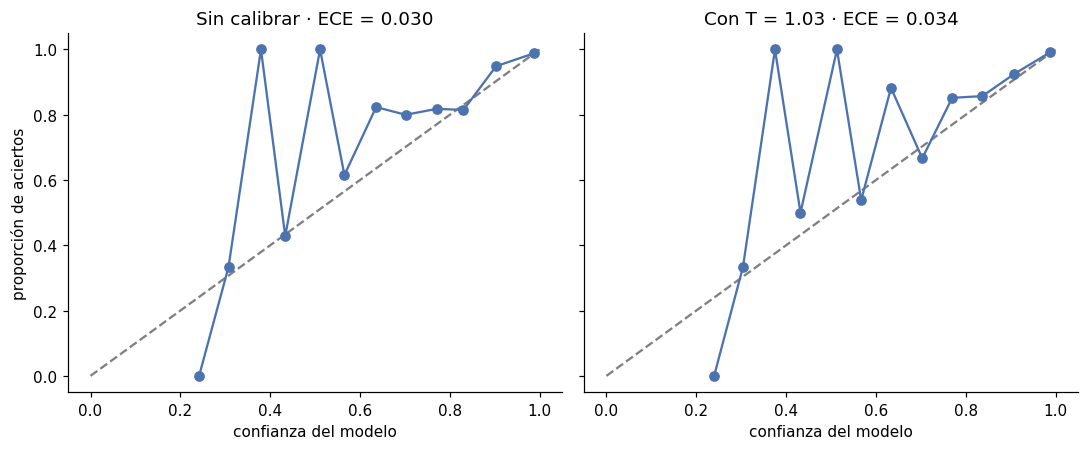

Confianza media: 90.9%   Acierto real: 93.6%


In [ ]:
P = oof[[f"prob_{c}" for c in CLASES]].to_numpy()
y = oof["clase"].map(IDX).to_numpy()
T_OPT = float(minimize(lambda t: nll(escalar(P, t[0]), y), x0=[1.0], bounds=[(0.05, 20.0)], method="L-BFGS-B").x[0])
P_CAL = escalar(P, T_OPT)

ece_antes, curva_antes = ece_y_curva(P, y)
ece_despues, curva_despues = ece_y_curva(P_CAL, y)
display(pd.DataFrame({"sin calibrar": [ece_antes, nll(P, y), brier(P, y)], f"con T = {T_OPT:.2f}": [ece_despues, nll(P_CAL, y), brier(P_CAL, y)]},
                     index=["ECE", "log-verosimilitud negativa", "Brier"]).round(4))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, curva, titulo in [(ejes[0], curva_antes, f"Sin calibrar · ECE = {ece_antes:.3f}"), (ejes[1], curva_despues, f"Con T = {T_OPT:.2f} · ECE = {ece_despues:.3f}")]:
    ax.plot([0, 1], [0, 1], ls="--", color="gray")
    ax.plot(curva[:, 0], curva[:, 1], marker="o", color="#4C72B0")
    ax.set_title(titulo); ax.set_xlabel("confianza del modelo")
ejes[0].set_ylabel("proporción de aciertos")
fig.tight_layout()
plt.show()
print(f"Confianza media: {P.max(axis=1).mean():.1%}   Acierto real: {(P.argmax(axis=1) == y).mean():.1%}")

La confianza media es 90,9 % y el acierto real 93,6 %: en promedio el modelo no es sobreconfiado. Entre 0,55 y 0,85 de confianza el acierto queda sobre o por encima de la diagonal; los puntos por debajo de 0,5 tienen muy pocas imágenes y saltan demasiado para leerlos.

La mejor temperatura es T = 1,03, prácticamente 1, y no cambia casi nada: el ECE pasa de 0,030 a 0,034, y la log-verosimilitud y el Brier quedan iguales. El ECE puede empeorar un poco porque T se elige minimizando la log-verosimilitud, no el ECE. El modelo ya estaba razonablemente calibrado.

### La calibración de P(H2)

Lo anterior mide la confianza en la clase elegida. Para priorizar se usa otra cosa: la P(H2) de cada imagen, sea cual sea su clase predicha. La figura repite la comprobación solo con ella: las imágenes se agrupan por su P(H2) y en cada cajón se compara la P(H2) promedio con la proporción que de verdad es H2. Se usan 10 cajones, porque hay solo 50 H2, y junto a cada punto va el número de imágenes.

El escalado por temperatura divide todas las salidas por el mismo número T. Dentro de cada imagen no cambia qué clase gana: solo hace las probabilidades más parejas (T mayor que 1) o más extremas (T menor que 1). Entre imágenes, el orden por P(H2) se conserva casi siempre. Solo pueden intercambiarse dos imágenes con P(H2) muy parecidas en las que H2 compite de forma distinta, por ejemplo con un único rival en una y con varios en la otra. Con una temperatura cercana a 1 esos cambios son raros, así que para ordenar, calibrar o no da igual. Importa en los cortes de las franjas de prioridad (sección 4.8), que son valores de P(H2) y conviene poder leerlos como probabilidades.

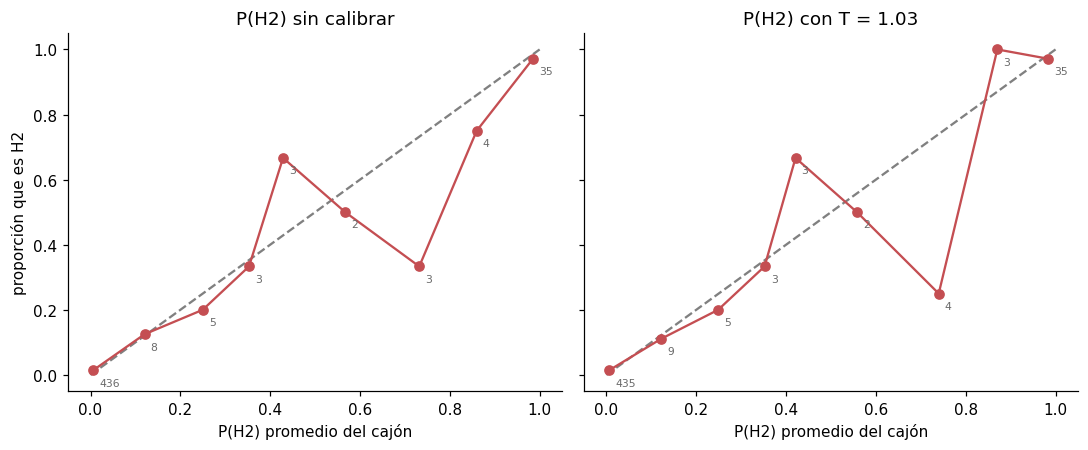

In [ ]:
def fiabilidad(p, es_clase, bins=10):
    filas = []
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
        if m.any():
            filas.append((p[m].mean(), es_clase[m].mean(), int(m.sum())))
    return np.array(filas)

es_h2_cv = (y == IDX["H2"]).astype(float)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, p, titulo in [(ejes[0], P[:, IDX["H2"]], "P(H2) sin calibrar"), (ejes[1], P_CAL[:, IDX["H2"]], f"P(H2) con T = {T_OPT:.2f}")]:
    f = fiabilidad(p, es_h2_cv)
    ax.plot([0, 1], [0, 1], ls="--", color="gray")
    ax.plot(f[:, 0], f[:, 1], marker="o", color="#C44E52")
    for xm, ym, n in f:
        ax.annotate(int(n), (xm, ym), textcoords="offset points", xytext=(4, -10), fontsize=7, color="dimgray")
    ax.set_title(titulo); ax.set_xlabel("P(H2) promedio del cajón")
ejes[0].set_ylabel("proporción que es H2")
fig.tight_layout()
plt.show()

Casi todas las imágenes están en los extremos: 436 en el primer cajón (P(H2) cercana a 0, y solo un 1,4 % son H2) y 35 en el último (P(H2) cercana a 1, y el 97 % son H2). En esos dos cajones, que reúnen el 94 % de las imágenes, P(H2) se puede leer casi literalmente como probabilidad. Entre 0,2 y 0,9 hay de 2 a 5 imágenes por cajón y los puntos saltan a ambos lados de la diagonal sin patrón: con tan pocas imágenes no se puede decir si ahí el modelo está bien o mal calibrado. Una P(H2) intermedia debe leerse como zona de duda, no como un porcentaje preciso.

## 4.4 Evaluación del holdout

Aquí, y solo aquí, se cargan las imágenes del holdout: las 101 que se apartaron en el notebook 1 y que no intervinieron en ninguna decisión (ni en el entrenamiento, ni en la elección del modelo, ni en la calibración). Es la estimación más honesta de cómo funciona el modelo con imágenes nuevas.

Se evalúa con el modelo congelado de la sección 4.2, una sola vez, y nada se ajusta después de ver el resultado. Las predicciones se guardan en `salidas/holdout_predicciones.csv`; si el notebook se vuelve a ejecutar, se leen de ahí en lugar de evaluar de nuevo.

Con 10 u 11 imágenes por clase, un solo error mueve mucho una métrica, así que cada resultado va con un **intervalo de confianza del 95 %** calculado por **bootstrap**: se arma un holdout alternativo sorteando con reposición del holdout real, se recalcula la métrica, se repite 2000 veces, y el intervalo es el rango que contiene el 95 % central de esos valores. Lo que se sortea son **sitios** (los grupos del notebook 1) dentro de cada clase, no imágenes sueltas: las imágenes de un mismo sitio se parecen y no aportan información independiente, y sortearlas por separado daría intervalos más estrechos de lo que corresponde.

El resultado se compara además con el rango de los cinco pliegues de la validación cruzada.

In [ ]:
ruta_holdout = OUT_DIR / "holdout_predicciones.csv"
if ruta_holdout.exists():
    pred_ho = pd.read_csv(ruta_holdout, sep=";", encoding="utf-8-sig")
else:
    ho = part[part["split"] == "holdout"].reset_index(drop=True)
    prob = probabilidades(MODELO_FINAL, [cargar_reducida(DATASET_DIR / c / f"{i}.png") for c, i in zip(ho["carpeta"], ho["id"])])
    pred_ho = ho[["id", "clase", "grupo_particion", "zoom"]].copy()
    pred_ho["pred"] = [CLASES[i] for i in prob.argmax(1)]
    pred_ho = pd.concat([pred_ho, pd.DataFrame(prob, columns=[f"prob_{c}" for c in CLASES])], axis=1)
    pred_ho.to_csv(ruta_holdout, sep=";", index=False, encoding="utf-8-sig")

y_ho = pred_ho["clase"].map(IDX).to_numpy()
p_ho = pred_ho["pred"].map(IDX).to_numpy()
prob_ho = pred_ho[[f"prob_{c}" for c in CLASES]].to_numpy()
i_h2 = IDX["H2"]

def metricas_holdout(y_, p_, prob_h2):
    return {"F1-macro (10 clases)": f1_score(y_, p_, labels=range(len(CLASES)), average="macro", zero_division=0),
            "Exactitud balanceada": balanced_accuracy_score(y_, p_),
            "F1 de H2": f1_score(y_ == i_h2, p_ == i_h2, zero_division=0),
            "PR-AUC de H2": average_precision_score(y_ == i_h2, prob_h2)}

# bootstrap por sitios, dentro de cada clase
grupos = pred_ho["grupo_particion"].to_numpy()
grupos_por_clase = [np.unique(grupos[y_ho == c]) for c in range(len(CLASES))]
filas_de_grupo = {g: np.where(grupos == g)[0] for g in np.unique(grupos)}
rng = np.random.default_rng(SEMILLA)
remuestreos = []
for _ in range(N_REMUESTREOS):
    idx = np.concatenate([filas_de_grupo[g] for gs in grupos_por_clase for g in rng.choice(gs, size=len(gs), replace=True)])
    remuestreos.append(metricas_holdout(y_ho[idx], p_ho[idx], prob_ho[idx, i_h2]))
remuestreos = pd.DataFrame(remuestreos)
display(pd.DataFrame({"holdout": pd.Series(metricas_holdout(y_ho, p_ho, prob_ho[:, i_h2])),
                      "IC 95 % inferior": remuestreos.quantile(0.025), "IC 95 % superior": remuestreos.quantile(0.975)}).round(3))
print("Sitios del holdout por clase:", ", ".join(f"{CLASES[c]} {len(gs)}" for c, gs in enumerate(grupos_por_clase)))

f1_pliegues = pd.Series({k: f1_score(g["clase"], g["pred"], labels=COMPARABLES, average="macro", zero_division=0) for k, g in oof.groupby("pliegue")})
f1_ho_9 = f1_score([CLASES[i] for i in y_ho], [CLASES[i] for i in p_ho], labels=COMPARABLES, average="macro", zero_division=0)
print(f"F1-macro en las {len(COMPARABLES)} clases comparables. Holdout: {f1_ho_9:.3f}   "
      f"Validación cruzada: {f1_pliegues.mean():.3f} ± {f1_pliegues.std():.3f} (de {f1_pliegues.min():.3f} a {f1_pliegues.max():.3f})")

,holdout,IC 95 % inferior,IC 95 % superior
F1-macro (10 clases),0.919,0.866,0.966
Exactitud balanceada,0.920,0.871,0.969
F1 de H2,0.857,0.667,1.000
PR-AUC de H2,0.949,0.822,1.000


Sitios del holdout por clase: Fairy circle 1, Fairy fort 7, Farm circle 8, Flooded dune 10, H2 8, Impact crater 10, Jaguey 9, Karst 6, Salt lake 10, Thermokarst 9
F1-macro en las 9 clases comparables. Holdout: 0.910   Validación cruzada: 0.936 ± 0.040 (de 0.893 a 0.976)


Sobre las 9 clases comparables, el F1-macro del holdout es 0,910: dentro del rango de los cinco pliegues (0,893 a 0,976), pero por debajo de su media (0,936) y cerca del pliegue más bajo. Con las 10 clases es 0,919, con un intervalo de 0,866 a 0,966. Es lo que cabe esperar de una validación cruzada algo optimista, como se advirtió en el notebook 3. La diferencia es pequeña, pero la cifra que debe citarse como desempeño esperado con imágenes nuevas de estas mismas regiones es la del holdout.

Para H2, el F1 es 0,857 y la PR-AUC 0,949, con intervalos anchos (0,67 a 1,00 y 0,82 a 1,00), porque sus 10 imágenes vienen de solo 8 sitios. Fairy circle es un único sitio, así que al sortear sitios su resultado no varía: su 1,00 no dice nada sobre sitios nuevos.

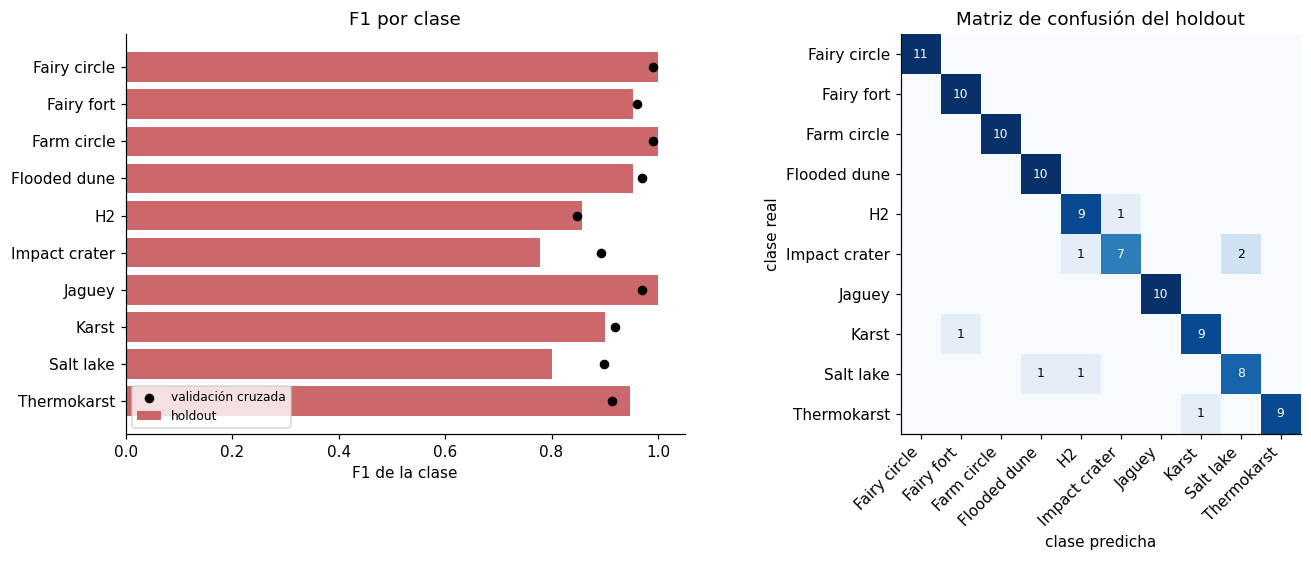

,precisión,recall,F1,imágenes
Fairy circle,1.000,1.0,1.000,11
Fairy fort,0.909,1.0,0.952,10
Farm circle,1.000,1.0,1.000,10
Flooded dune,0.909,1.0,0.952,10
H2,0.818,0.9,0.857,10
Impact crater,0.875,0.7,0.778,10
Jaguey,1.000,1.0,1.000,10
Karst,0.900,0.9,0.900,10
Salt lake,0.800,0.8,0.800,10
Thermokarst,1.000,0.9,0.947,10


In [ ]:
prec, rec, f1c, sop = precision_recall_fscore_support(y_ho, p_ho, labels=range(len(CLASES)), zero_division=0)
f1_cv = pd.Series(precision_recall_fscore_support(oof["clase"], oof["pred"], labels=CLASES, zero_division=0)[2], index=CLASES)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
ejes[0].barh(CLASES, f1c, color="#C44E52", alpha=0.85, label="holdout")
ejes[0].scatter(f1_cv, CLASES, color="black", s=28, zorder=3, label="validación cruzada")
ejes[0].set_xlim(0, 1.05); ejes[0].invert_yaxis(); ejes[0].set_xlabel("F1 de la clase"); ejes[0].legend(fontsize=8, loc="lower left")
ejes[0].set_title("F1 por clase")

cm = confusion_matrix(y_ho, p_ho, labels=range(len(CLASES)))
ejes[1].imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ejes[1].set_xticks(range(len(CLASES)), CLASES, rotation=45, ha="right"); ejes[1].set_yticks(range(len(CLASES)), CLASES)
for (i, j), n in np.ndenumerate(cm):
    if n:
        ejes[1].text(j, i, n, ha="center", va="center", fontsize=8, color="white" if n / cm[i].sum() > 0.5 else "black")
ejes[1].set_xlabel("clase predicha"); ejes[1].set_ylabel("clase real"); ejes[1].set_title("Matriz de confusión del holdout")
fig.tight_layout()
plt.show()
display(pd.DataFrame({"precisión": prec, "recall": rec, "F1": f1c, "imágenes": sop}, index=CLASES).round(3))

Las clases más débiles en el holdout son Impact crater (F1 0,78, recall 0,70) y Salt lake (0,80); en validación cruzada eran H2 (0,85), Impact crater (0,89) y Salt lake (0,90). De las 10 H2 del holdout se aciertan 9, y la que falla se predice como Impact crater. Hay dos falsos positivos de H2, un Impact crater y un Salt lake, que dejan la precisión en 0,82. Ningún Jagüey se confunde con H2 ni al revés. Con 10 imágenes por clase, cada error mueve el F1 de una clase entre 5 y 10 puntos, así que las diferencias entre clases no son definitivas.

La calibración también se puede comprobar en el holdout, que no se usó para ajustar `T`:

In [ ]:
print(f"ECE en el holdout: {ece_y_curva(prob_ho, y_ho)[0]:.3f} sin calibrar y {ece_y_curva(escalar(prob_ho, T_OPT), y_ho)[0]:.3f} con T = {T_OPT:.2f}."
      f"  Confianza media {prob_ho.max(1).mean():.1%}, acierto {(p_ho == y_ho).mean():.1%}")

ECE en el holdout: 0.056 sin calibrar y 0.059 con T = 1.03.  Confianza media 94.1%, acierto 92.1%


En el holdout la confianza media es 94,1 % y el acierto 92,1 %: aquí el modelo sí queda algo sobreconfiado. El ECE es 0,056 sin calibrar y 0,059 con la temperatura. Con 101 imágenes esas diferencias son ruido; lo que muestran es que la temperatura no aporta nada.

## 4.5 ¿Aprende la forma o el entorno?

Un modelo puede acertar porque reconoce la forma de la geoforma o porque reconoce lo que la rodea: el color del suelo, la vegetación, el paisaje de una región. Lo segundo funciona mientras las imágenes nuevas se parezcan a las de entrenamiento. Para separar las dos cosas se alteran a propósito las imágenes de validación (cada una evaluada por el modelo del pliegue en que quedó apartada) y se mide cuánto cae el desempeño:

- **Sin color (grises):** ¿depende del color del terreno?
- **Solo el centro:** se conserva un disco central de diámetro igual al 60 % del lado y el resto se cubre con el color medio de la imagen. Queda visible casi solo la estructura.
- **Solo el entorno:** se tapa ese disco y se deja el resto. Si el modelo sigue acertando sin ver la estructura, clasifica por el entorno.

Tapar con un color plano mete en la imagen algo que el modelo nunca vio: un disco liso de borde nítido. Si el desempeño cae, puede ser porque faltaba información o porque el disco desconcierta al modelo. Para distinguirlo hay dos **controles** que borran la misma información sin dejar borde: se **desenfoca** la zona (cada píxel se reemplaza por el promedio de sus vecinos hasta un radio del 20 % del lado), de modo que la forma deja de leerse pero el color y la textura gruesa se conservan.

- **Centro desenfocado:** la versión sin borde de «solo el entorno».
- **Entorno desenfocado:** la versión sin borde de «solo el centro».

Si cada condición y su control dan lo mismo, la caída es pérdida real de información. La condición sin color no tiene control: como el modelo nunca se entrenó con imágenes en grises, su caída mezcla la dependencia del color con la novedad de ver una imagen gris, y se lee como un máximo.

La tabla da el F1-macro de cada condición y su caída; el mapa de colores, el recall de cada clase. Como el recall solo puede engañar (si el modelo empezara a llamar H2 a todo, el recall de H2 seguiría alto), para H2 y Jagüey se da también la precisión y cuántas imágenes de otras clases se predijeron como ellas. El «centro» es un disco fijo y no el contorno real de cada estructura, que no está disponible.

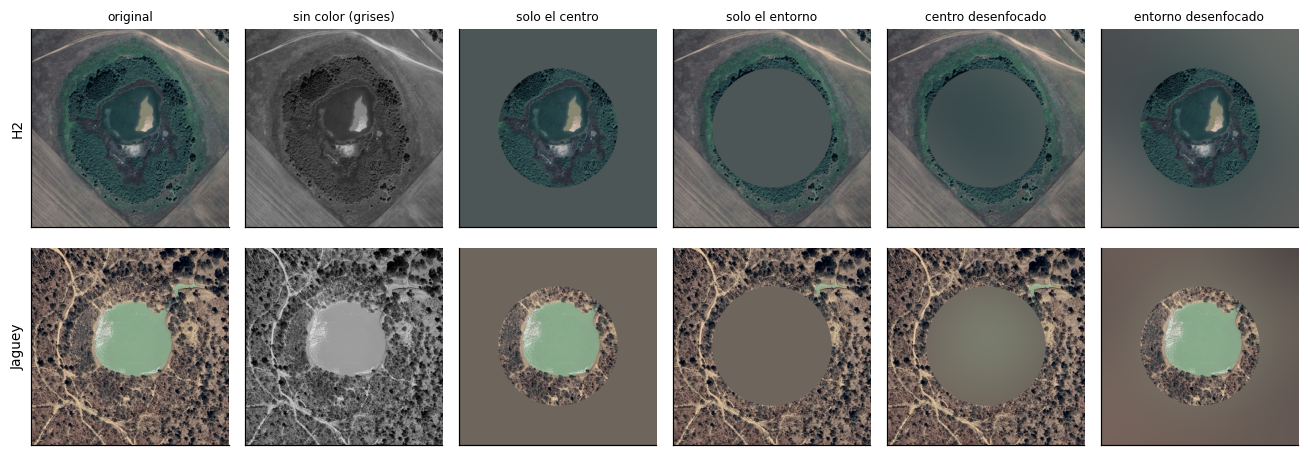

In [ ]:
ejemplos = [int(cv[cv["clase"] == c]["id"].iloc[0]) for c in ("H2", "Jaguey")]
fig, ejes = plt.subplots(len(ejemplos), len(ALTERACIONES), figsize=(2.0 * len(ALTERACIONES), 2.2 * len(ejemplos)))
for f, ident in enumerate(ejemplos):
    for c, (nombre, alterar) in enumerate(ALTERACIONES.items()):
        ejes[f, c].imshow(alterar(CACHE[ident])); ejes[f, c].set_xticks([]); ejes[f, c].set_yticks([])
        if f == 0:
            ejes[f, c].set_title(nombre, fontsize=8)
    ejes[f, 0].set_ylabel(cv.loc[cv["id"] == ident, "clase"].iloc[0], fontsize=9)
fig.tight_layout()
plt.show()

,F1-macro,desviación,exactitud balanceada,caída de F1-macro
condicion,,,,
original,0.936,0.040,0.936,0.000
sin color (grises),0.767,0.100,0.786,0.169
solo el centro,0.717,0.077,0.736,0.219
solo el entorno,0.826,0.026,0.836,0.110
centro desenfocado,0.839,0.029,0.846,0.097
entorno desenfocado,0.704,0.084,0.726,0.232


H2                                     Jaguey                                 
                    precisión recall otras predichas como ésta precisión recall otras predichas como ésta
condición                                                                                                
original                 0.86   0.84                         7      0.98   0.96                         1
sin color (grises)       0.71   0.80                        16      0.97   0.68                         1
solo el centro           0.63   0.82                        24      0.84   0.74                         7
solo el entorno          0.85   0.80                         7      1.00   0.80                         0
centro desenfocado       0.85   0.80                         7      1.00   0.80                         0
entorno desenfocado      0.63   0.82                        24      0.82   0.74                         8

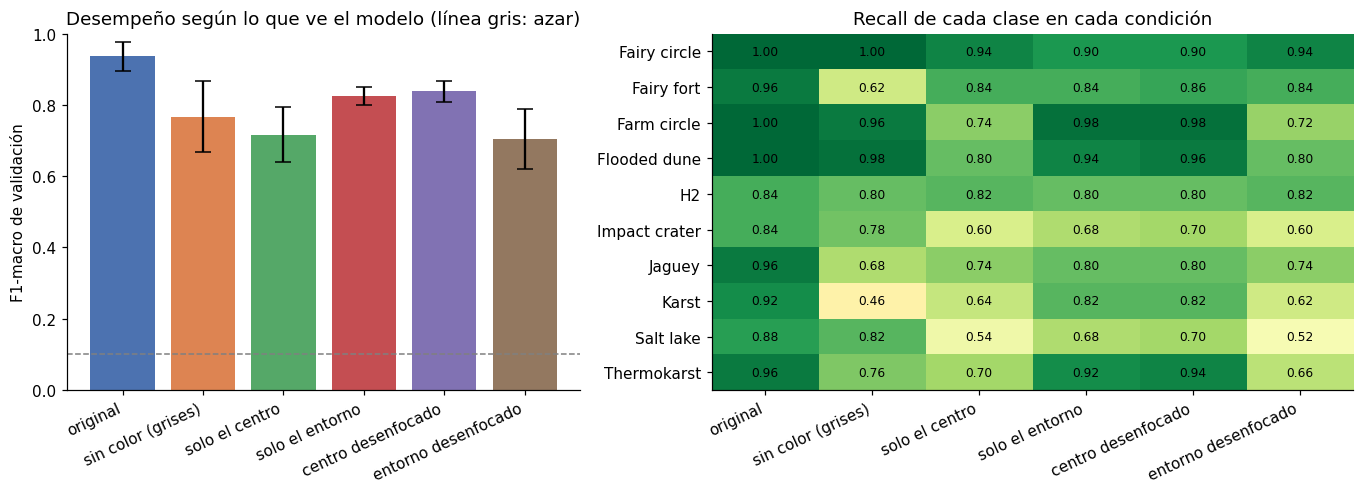

In [ ]:
modelos_pliegue = {k: cargar_modelo(OUT_DIR / "modelos" / f"{VARIANTE}_pliegue{k}.pt") for k in range(1, N_PLIEGUES + 1)}
filas = []
for nombre, alterar in ALTERACIONES.items():
    for k, red in modelos_pliegue.items():
        val = cv[cv["fold_val"] == k]
        prob = probabilidades(red, [alterar(CACHE[int(i)]) for i in val["id"]])
        filas.append(pd.DataFrame({"id": val["id"].to_numpy(), "clase": val["clase"].to_numpy(), "pliegue": k,
                                   "condicion": nombre, "pred": [CLASES[i] for i in prob.argmax(1)]}))
ctx = pd.concat(filas, ignore_index=True)
assert (ctx[ctx["condicion"] == "original"].merge(oof[["id", "pred"]], on="id", suffixes=("", "_nb3")).eval("pred == pred_nb3")).all()

def resumen_condicion(g):
    f1 = pd.Series({k: f1_score(s["clase"], s["pred"], labels=COMPARABLES, average="macro", zero_division=0) for k, s in g.groupby("pliegue")})
    return pd.Series({"F1-macro": f1.mean(), "desviación": f1.std(), "exactitud balanceada": balanced_accuracy_score(g["clase"], g["pred"])})
tabla_ctx = ctx.groupby("condicion").apply(resumen_condicion, include_groups=False).reindex(list(ALTERACIONES))
tabla_ctx["caída de F1-macro"] = tabla_ctx.loc["original", "F1-macro"] - tabla_ctx["F1-macro"]
display(tabla_ctx.round(3))

filas = []
for nombre, g in ctx.groupby("condicion", sort=False):
    fila = {"condición": nombre}
    for clase in ("H2", "Jaguey"):
        p_, r_, _, _ = precision_recall_fscore_support(g["clase"], g["pred"], labels=[clase], zero_division=0)
        fila[(clase, "precisión")], fila[(clase, "recall")] = p_[0], r_[0]
        fila[(clase, "otras predichas como ésta")] = int(((g["pred"] == clase) & (g["clase"] != clase)).sum())
    filas.append(fila)
tabla_hj = pd.DataFrame(filas).set_index("condición")
tabla_hj.columns = pd.MultiIndex.from_tuples(tabla_hj.columns)
display(tabla_hj.round(2))

recall_ctx = pd.DataFrame({n: precision_recall_fscore_support(g["clase"], g["pred"], labels=CLASES, zero_division=0)[1]
                           for n, g in ctx.groupby("condicion")}, index=CLASES)[list(ALTERACIONES)]
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ejes[0].bar(range(len(tabla_ctx)), tabla_ctx["F1-macro"], yerr=tabla_ctx["desviación"], capsize=5,
            color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"])
ejes[0].axhline(1 / len(CLASES), color="gray", ls="--", lw=1)
ejes[0].set_xticks(range(len(tabla_ctx)), tabla_ctx.index, rotation=25, ha="right"); ejes[0].set_ylim(0, 1)
ejes[0].set_ylabel("F1-macro de validación"); ejes[0].set_title("Desempeño según lo que ve el modelo (línea gris: azar)")
ejes[1].imshow(recall_ctx.to_numpy(), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ejes[1].set_xticks(range(recall_ctx.shape[1]), recall_ctx.columns, rotation=25, ha="right"); ejes[1].set_yticks(range(len(CLASES)), CLASES)
for (i, j), v in np.ndenumerate(recall_ctx.to_numpy()):
    ejes[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
ejes[1].set_title("Recall de cada clase en cada condición")
fig.tight_layout()
plt.show()

Quitar el color baja el F1-macro de 0,936 a 0,767, de forma desigual: Karst pasa de 0,92 a 0,46 de recall, Fairy fort de 0,96 a 0,62 y Jagüey de 0,96 a 0,68, mientras que Fairy circle, Farm circle, Flooded dune y H2 casi no cambian.

Dejar solo el centro baja el F1-macro a 0,717, y dejar solo el entorno, a 0,826: con la estructura tapada el modelo rinde más que con solo la estructura a la vista. Los controles descartan que sea un efecto del disco liso: desenfocar el centro da 0,839 (frente a 0,826) y desenfocar el entorno, 0,704 (frente a 0,717). Las dos diferencias son de 0,013, muy por debajo de la desviación entre pliegues, y clase por clase el recall de cada condición y el de su control no se separan más de 0,02. Las caídas son pérdida real de información.

La asimetría es real: perder el entorno cuesta unos 0,23 de F1-macro y perder la estructura, unos 0,10. El caso más marcado es Salt lake, cuyo recall cae de 0,88 a 0,54 con solo la estructura visible; le siguen Impact crater (0,84 a 0,60), Karst (0,92 a 0,64), Thermokarst (0,96 a 0,70) y Farm circle (1,00 a 0,74). Varias de esas clases se reconocen casi igual de bien con la estructura tapada (Farm circle 0,98, Flooded dune 0,94, Thermokarst 0,92): para ellas el entorno por sí solo alcanza. En las estructuras que llenan el cuadro parte de la estructura queda fuera del disco, así que «solo el entorno» no la elimina del todo.

H2 se mantiene entre 0,80 y 0,84 de recall en las seis condiciones, pero su precisión no. Con solo el centro visible, 24 imágenes de otras clases pasan a predecirse como H2 (7 en la original) y la precisión baja de 0,86 a 0,63; con el entorno desenfocado pasa lo mismo (24 imágenes, 0,63), y sin color algo menos (16, 0,71). Cuando al modelo le falta el paisaje, H2 se vuelve una clase refugio adonde van las estructuras aisladas que no sabe clasificar; la estabilidad de su recall no demuestra que la reconozca por su forma. Jagüey se comporta al revés: casi nunca atrae imágenes de otras clases (precisión entre 0,82 y 1,00) y lo que pierde es recall, que baja a 0,80 con la estructura tapada, a 0,74 con solo la estructura y a 0,68 sin color.

## 4.6 Estructura y paisaje en conflicto

El modelo se apoya en el paisaje, y en este dataset todo lo que tiene paisaje de La Guajira es Jagüey; ninguna H2 viene de allí. Las 120 estructuras a priorizar están en La Guajira. La pregunta práctica es si una estructura con forma de H2 sobre un paisaje guajiro sería arrastrada hacia Jagüey.

Para medirlo se hacen **montajes**: el disco central de una imagen (el de la sección 4.5, con el borde suavizado) se pega sobre el entorno de otra. Dentro de cada pliegue se combinan todas las estructuras con todos los paisajes de sus imágenes de validación, y se clasifican con el modelo de ese pliegue, que no vio ninguna de las dos. Las condiciones son:

- **H2 sobre el paisaje de otra H2** y **Jagüey sobre el paisaje de otro Jagüey**: controles que miden el efecto del montaje en sí.
- **H2 sobre paisaje guajiro** (el entorno de un Jagüey) y **Jagüey sobre el paisaje de una H2**: estructura y paisaje apuntan a clases distintas.

La diferencia entre cada montaje en conflicto y su control es el efecto del paisaje. H2 y Jagüey se capturaron con zooms algo distintos, así que en el montaje la estructura y el paisaje pueden no estar a la misma escala.

,montajes,predichos H2,predichos Jagüey,P(H2) promedio,P(Jagüey) promedio
condicion,,,,,
H2 sobre paisaje de otra H2 (control),532,0.844,0.002,0.789,0.009
H2 sobre paisaje guajiro,512,0.330,0.492,0.321,0.422
Jagüey sobre paisaje de otro Jagüey (control),474,0.011,0.943,0.015,0.895
Jagüey sobre paisaje de una H2,512,0.320,0.449,0.289,0.387


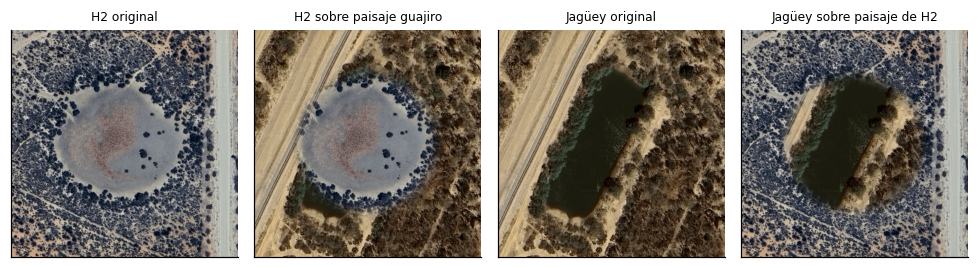

In [ ]:
filas = []
for k, red in modelos_pliegue.items():
    val = cv[cv["fold_val"] == k]
    h2_k = val.loc[val["clase"] == "H2", "id"].astype(int).tolist()
    jag_k = val.loc[val["clase"] == "Jaguey", "id"].astype(int).tolist()
    combinaciones = {
        "H2 sobre paisaje de otra H2 (control)": [(a, b) for a in h2_k for b in h2_k if a != b],
        "H2 sobre paisaje guajiro": [(a, b) for a in h2_k for b in jag_k],
        "Jagüey sobre paisaje de otro Jagüey (control)": [(a, b) for a in jag_k for b in jag_k if a != b],
        "Jagüey sobre paisaje de una H2": [(a, b) for a in jag_k for b in h2_k],
    }
    for nombre, pares in combinaciones.items():
        prob = probabilidades(red, [montar(CACHE[a], CACHE[b]) for a, b in pares])
        filas.append(pd.DataFrame({"condicion": nombre, "pred": [CLASES[i] for i in prob.argmax(1)],
                                   "P(H2)": prob[:, IDX["H2"]], "P(Jagüey)": prob[:, IDX["Jaguey"]]}))
montajes = pd.concat(filas, ignore_index=True)
tabla_m = montajes.groupby("condicion", sort=False).agg(**{
    "montajes": ("pred", "size"), "predichos H2": ("pred", lambda s: (s == "H2").mean()),
    "predichos Jagüey": ("pred", lambda s: (s == "Jaguey").mean()), "P(H2) promedio": ("P(H2)", "mean"), "P(Jagüey) promedio": ("P(Jagüey)", "mean")})
display(tabla_m.round(3))

h2_1 = int(cv[(cv["clase"] == "H2") & (cv["fold_val"] == 1)]["id"].iloc[0])
jag_1 = int(cv[(cv["clase"] == "Jaguey") & (cv["fold_val"] == 1)]["id"].iloc[0])
fig, ejes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, im, titulo in zip(ejes, [CACHE[h2_1], montar(CACHE[h2_1], CACHE[jag_1]), CACHE[jag_1], montar(CACHE[jag_1], CACHE[h2_1])],
                          ["H2 original", "H2 sobre paisaje guajiro", "Jagüey original", "Jagüey sobre paisaje de H2"]):
    ax.imshow(im); ax.set_title(titulo, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

El efecto del paisaje es grande. Una H2 sobre el paisaje de otra H2 se sigue reconociendo en el 84 % de los montajes, como sin montaje, así que el montaje en sí no confunde al modelo. Pero sobre un paisaje guajiro la misma estructura solo se reconoce como H2 en el 33 %; en el 49 % el modelo dice Jagüey, y la P(H2) promedio cae de 0,79 a 0,32. Al revés pasa lo mismo: un Jagüey sobre el paisaje de otro Jagüey sale Jagüey en el 94 %, y sobre el paisaje de una H2 solo en el 45 %, con un 32 % que pasa a H2. En las dos direcciones, el paisaje decide la clase más o menos la mitad de las veces.

Para las 120 estructuras la consecuencia es directa. Todas tienen paisaje guajiro, así que el modelo tenderá a verlas como Jagüey y a darles una P(H2) menor que la que tendría la misma forma en otro lugar: en La Guajira una P(H2) moderada vale más de lo que parece, y una predicción de Jagüey no descarta una SCD. El montaje mide un sesgo promedio, no el de cada estructura. El paisaje guajiro no es uniforme (suelo, vegetación, otras depresiones cercanas), así que el arrastre hacia Jagüey puede variar de una candidata a otra. Por eso el orden entre las 120 se usa como prioridad bajo el supuesto de que ese sesgo es parecido para todas, no como un hecho comprobado. Parte del efecto puede venir de la diferencia de escala entre estructura y paisaje en el montaje.

## 4.7 Qué mira el modelo: mapas de calor

**Grad-CAM** dibuja sobre la imagen qué zonas pesaron más en la decisión: rojo mucho, azul poco. Toma el último bloque de la red que todavía conserva información espacial y mide cuánto cambia la respuesta al reforzar cada zona. Ese bloque tiene solo 7 × 7 posiciones, así que los mapas son de baja resolución y sirven como guía cualitativa, no como contorno. Se calcula para la clase predicha, con el modelo del pliegue en que la imagen quedó apartada, y solo sobre imágenes de validación cruzada.

Se muestran dos ejemplos acertados de cada clase y, más abajo, las H2 de cerca, junto con el **mapa medio** de cada clase (el promedio de los mapas de todas sus imágenes), que dice si el modelo mira sistemáticamente el centro, el anillo que lo rodea o los bordes del cuadro. Para resumirlo en un número se usa la **razón de concentración**: la fracción de la atención que cae dentro del disco central (el círculo punteado) dividida entre la fracción del área que ocupa ese disco. Vale 1 si la atención se reparte por igual y crece cuanto más se concentra en el centro. Supone que la estructura está centrada, como se capturó el dataset; una razón cercana a 1 no es un error en estructuras que llenan el cuadro o que están formadas por muchos elementos.

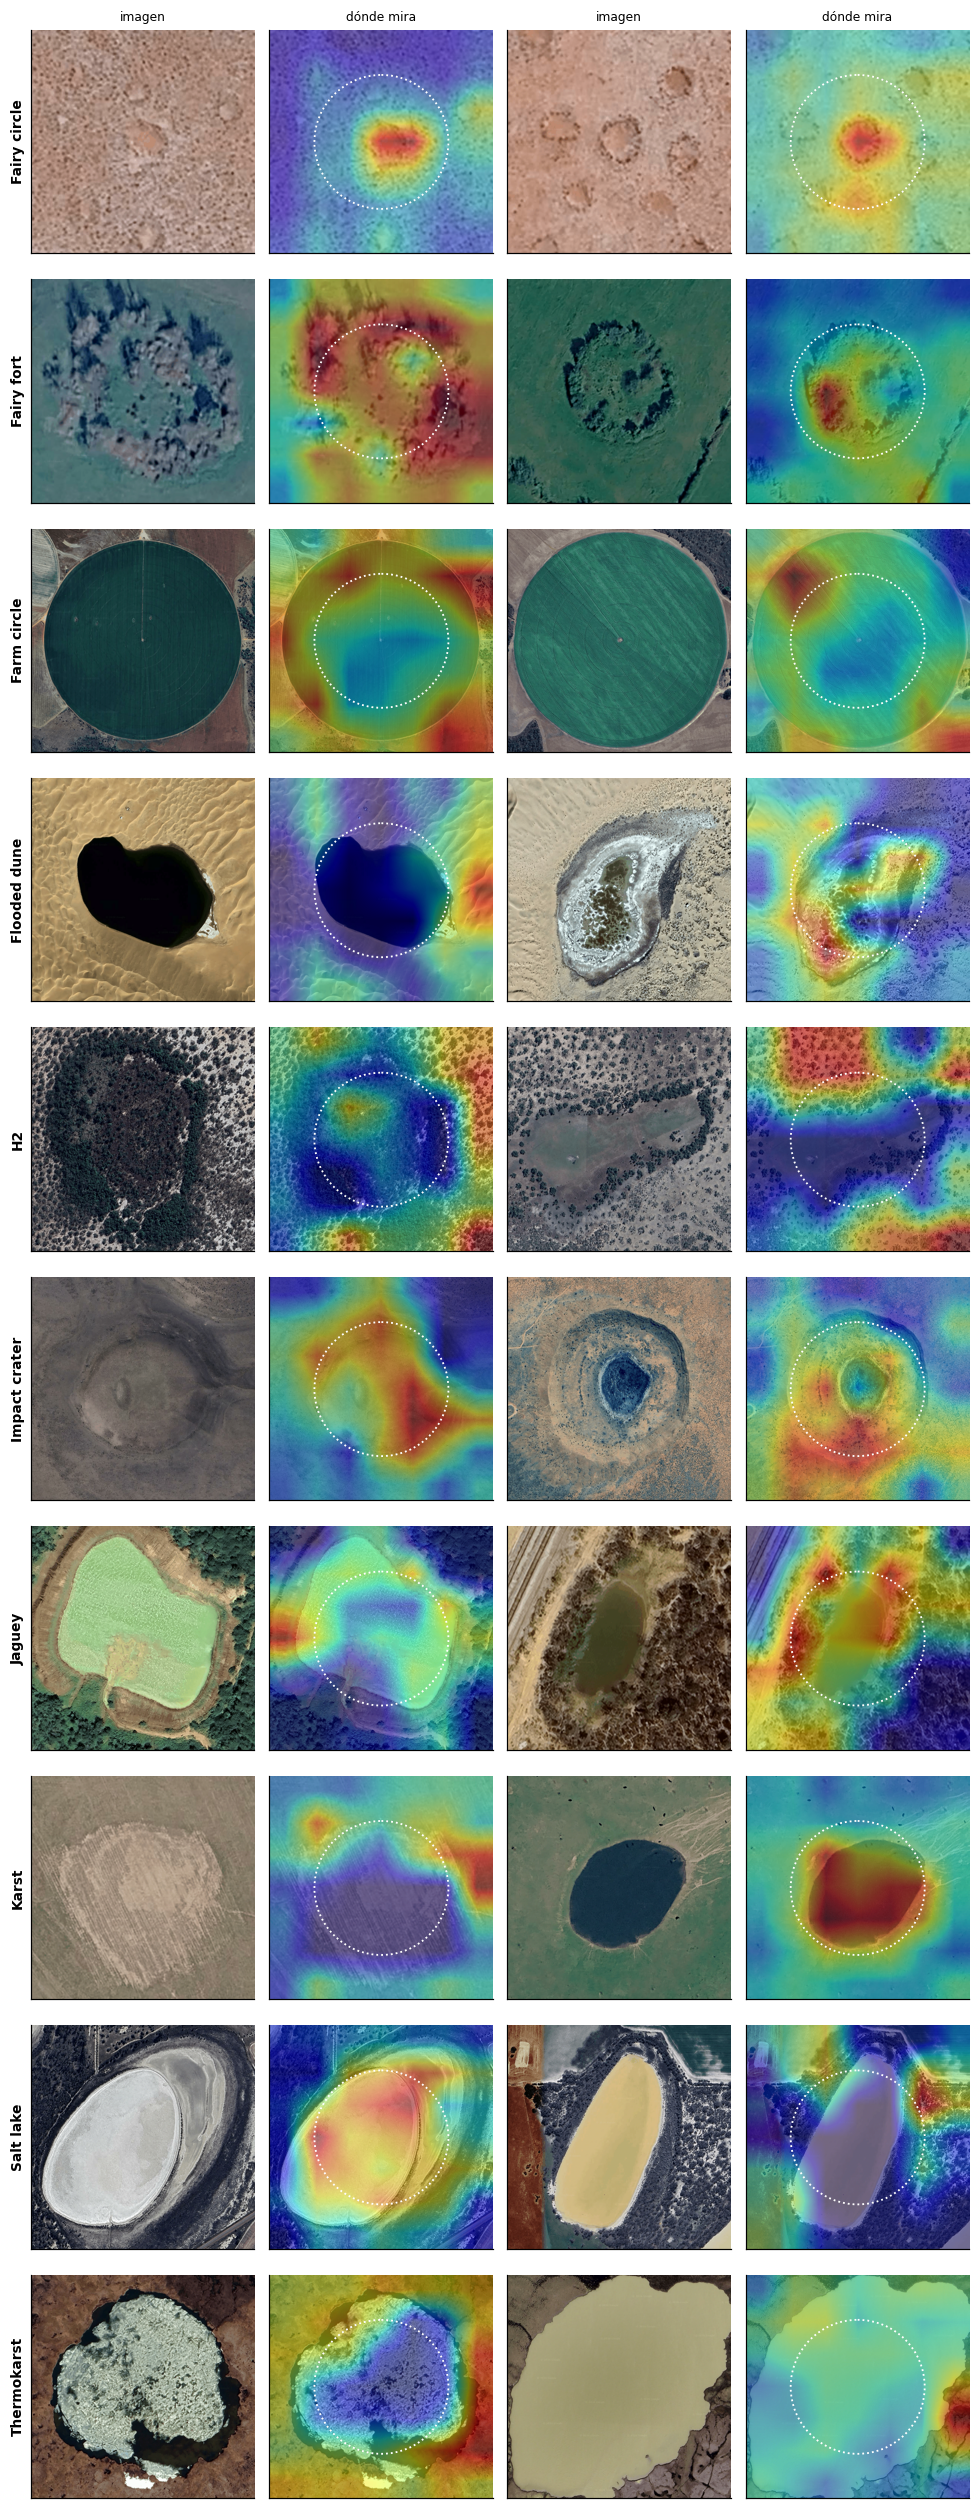

In [ ]:
cams, clases_pred = {}, {}
for k, red in modelos_pliegue.items():
    val = cv[cv["fold_val"] == k]
    cam, cl = gradcam(red, [CACHE[int(i)] for i in val["id"]])
    for i, c, cc in zip(val["id"], cam, cl):
        cams[int(i)], clases_pred[int(i)] = c, CLASES[int(cc)]

yy, xx = np.mgrid[:IMGSZ, :IMGSZ]
DISCO = ((xx - IMGSZ / 2) ** 2 + (yy - IMGSZ / 2) ** 2) <= (R_CENTRO * IMGSZ) ** 2
conc = pd.DataFrame({"id": list(cams)}).merge(cv[["id", "clase"]], on="id")
conc["razon"] = [float(cams[int(i)][DISCO].sum() / max(cams[int(i)].sum(), 1e-12) / DISCO.mean()) for i in conc["id"]]   # algún mapa puede salir todo en cero
conc["acierto"] = [clases_pred[int(i)] == c for i, c in zip(conc["id"], conc["clase"])]

def dibujar(ax, im, cam=None, titulo=None):
    ax.imshow(im.resize((IMGSZ, IMGSZ)))
    if cam is not None:
        ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.add_patch(plt.Circle((IMGSZ / 2, IMGSZ / 2), R_CENTRO * IMGSZ, fill=False, ec="white", ls=":", lw=1.2))
    ax.set_xticks([]); ax.set_yticks([])
    if titulo:
        ax.set_title(titulo, fontsize=8)

rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(len(CLASES), 4, figsize=(9, 2.3 * len(CLASES)))
for fila, clase in enumerate(CLASES):
    aciertos = conc[(conc["clase"] == clase) & conc["acierto"]]["id"].to_numpy()
    for j, i in enumerate(rng.choice(aciertos, size=min(2, len(aciertos)), replace=False)):
        dibujar(ejes[fila, 2 * j], CACHE[int(i)], titulo="imagen" if fila == 0 else None)
        dibujar(ejes[fila, 2 * j + 1], CACHE[int(i)], cams[int(i)], titulo="dónde mira" if fila == 0 else None)
    ejes[fila, 0].set_ylabel(clase, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

En varias clases el mapa coincide con la estructura: en Fairy circle marca los círculos, en Karst (segundo ejemplo) la depresión oscura del centro y en Salt lake el lago en un ejemplo y sus bordes en el otro. En otras el modelo mira sobre todo alrededor: en Farm circle se enciende en los bordes del campo y no en su interior, y en H2 la atención cae a menudo sobre la vegetación que rodea la depresión más que sobre la depresión misma.

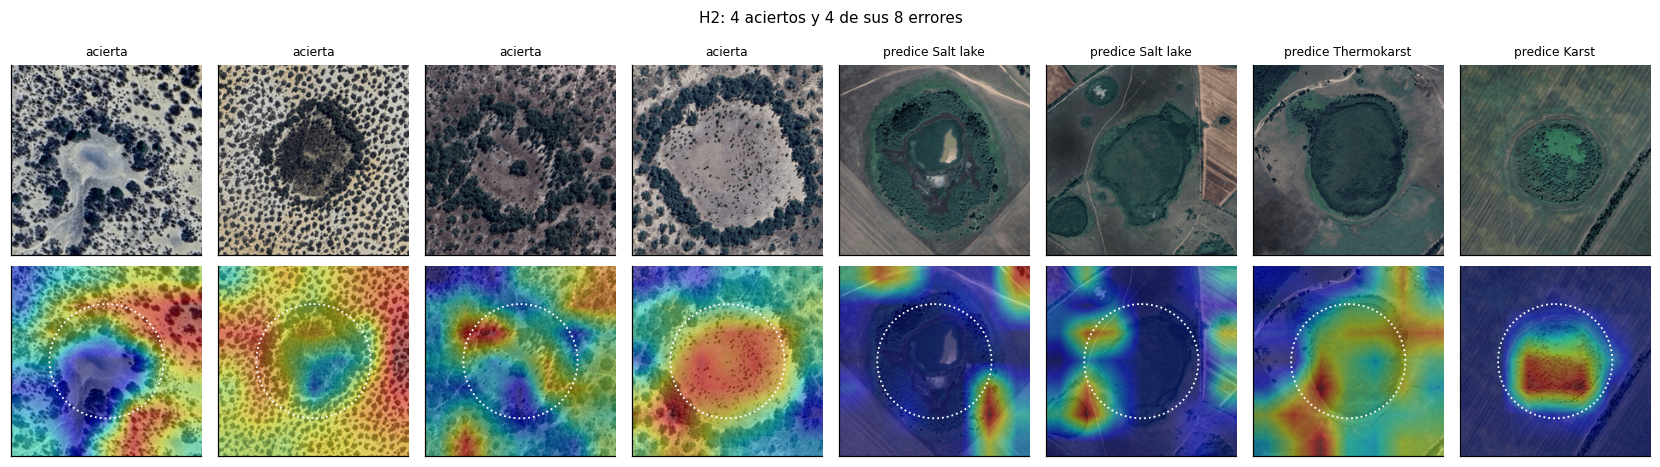

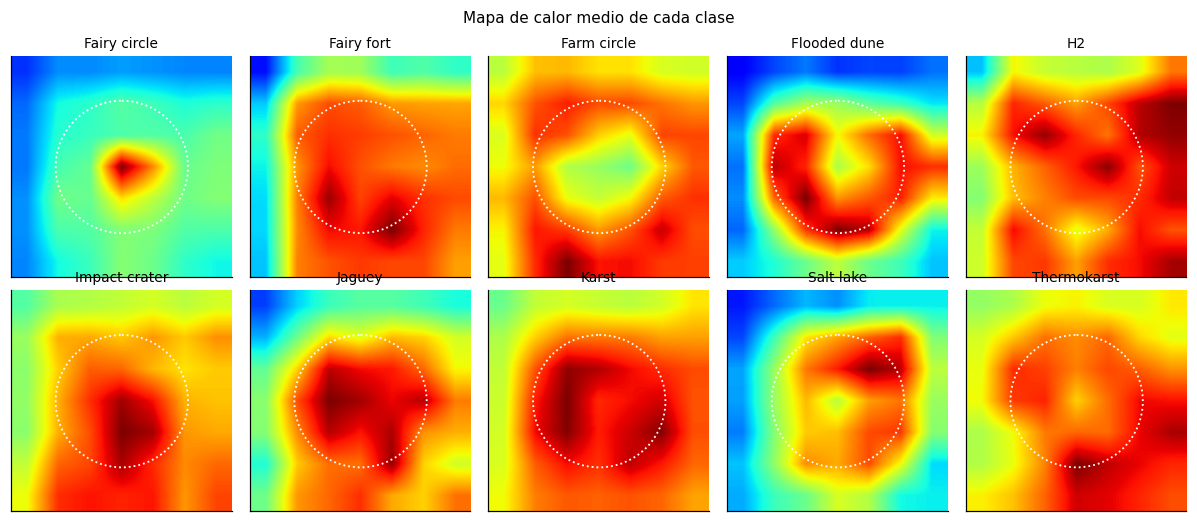

clase,Fairy circle,Fairy fort,Farm circle,Flooded dune,H2,Impact crater,Jaguey,Karst,Salt lake,Thermokarst
razón de concentración mediana,1.32,1.19,0.9,1.42,1.06,1.14,1.29,1.13,1.52,1.11


Razón mediana cuando el modelo acierta: 1.17; cuando se equivoca: 1.14


In [ ]:
h2 = conc[conc["clase"] == "H2"]
aciertos, errores = h2[h2["acierto"]]["id"].to_numpy(), h2[~h2["acierto"]]["id"].to_numpy()
elegidas = [(int(i), True) for i in rng.choice(aciertos, size=4, replace=False)] + [(int(i), False) for i in errores[:4]]
fig, ejes = plt.subplots(2, len(elegidas), figsize=(1.9 * len(elegidas), 4.4))
for j, (i, ok) in enumerate(elegidas):
    dibujar(ejes[0, j], CACHE[i], titulo="acierta" if ok else f"predice {clases_pred[i]}")
    dibujar(ejes[1, j], CACHE[i], cams[i])
fig.suptitle(f"H2: 4 aciertos y {min(4, len(errores))} de sus {len(errores)} errores", fontsize=10)
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(2, 5, figsize=(11, 4.8))
for ax, clase in zip(ejes.ravel(), CLASES):
    medio = np.mean([cams[int(i)] for i in cv.loc[cv["clase"] == clase, "id"]], axis=0)
    ax.imshow(medio / medio.max(), cmap="jet", vmin=0, vmax=1)
    ax.add_patch(plt.Circle((IMGSZ / 2, IMGSZ / 2), R_CENTRO * IMGSZ, fill=False, ec="white", ls=":", lw=1.2))
    ax.set_title(clase, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Mapa de calor medio de cada clase", fontsize=10)
fig.tight_layout()
plt.show()

razon_mediana = conc.groupby("clase")["razon"].median()
display(razon_mediana.round(2).rename("razón de concentración mediana").to_frame().T)
print(f"Razón mediana cuando el modelo acierta: {conc[conc['acierto']]['razon'].median():.2f}; cuando se equivoca: {conc[~conc['acierto']]['razon'].median():.2f}")

En los errores de H2 el modelo casi no mira el centro: en las cuatro imágenes mal clasificadas (dos veces Salt lake, Thermokarst y Karst) la atención está en los bordes o las esquinas, salvo en la última, donde sí marca el centro pero lo lee como Karst.

El mapa medio confirma lo que midieron las secciones 4.5 y 4.6. En Fairy circle la atención media es un punto en el centro; en Flooded dune y Farm circle, un anillo que coincide con el borde de la duna o del campo; en Impact crater, Jagüey y Karst, el centro y su entorno inmediato. H2 es la excepción: su atención se reparte por todo el cuadro, con los valores más altos fuera del disco central. Para reconocer una H2 el modelo mira sobre todo el paisaje que rodea a la depresión.

La razón de concentración mediana va de 0,90 en Farm circle a 1,52 en Salt lake, y en H2 es 1,06, atención casi repartida por igual. Aciertos y errores tienen medianas parecidas (1,17 y 1,14), así que esta medida no distingue un acierto de un error.

## 4.8 Franjas de prioridad

La metodología exige que los cortes entre las franjas alta, media y baja salgan del desarrollo del modelo y no de mirar las 120 estructuras; fijarlos después de verlas permitiría acomodarlos al resultado. Se fijan aquí, sobre la P(H2) calibrada de la validación cruzada, con dos criterios decididos antes de calcularlos:

- **Franja alta:** P(H2) igual o mayor que el menor corte a partir del cual la precisión es de al menos 90 % y no vuelve a bajar de ese valor para cortes más altos. En desarrollo, al menos 9 de cada 10 imágenes de esta franja eran H2.
- **Franja media:** P(H2) entre el mayor corte que todavía recupera al menos el 90 % de las H2 y el corte de la franja alta. Es la zona donde está casi todo lo que falta por encontrar, mezclado con otras clases.
- **Franja baja:** el resto.

La precisión de la franja alta se midió en un conjunto donde 1 de cada 10 imágenes es H2; entre las 120 estructuras de La Guajira esa proporción es desconocida, así que la franja la define el corte, no el porcentaje. La tabla muestra también cómo quedan en esas franjas las imágenes del holdout, usando sus predicciones ya guardadas; los cortes se fijaron sin mirarlas.

Franja alta: P(H2) ≥ 0.710.  Franja media: 0.092 ≤ P(H2) < 0.710.  Franja baja: P(H2) < 0.092.


franja alta       franja media       franja baja      
                            H2 otras           H2 otras          H2 otras
validación cruzada          38     4            7    17           5   428
holdout                      9     2            0     2           1    87

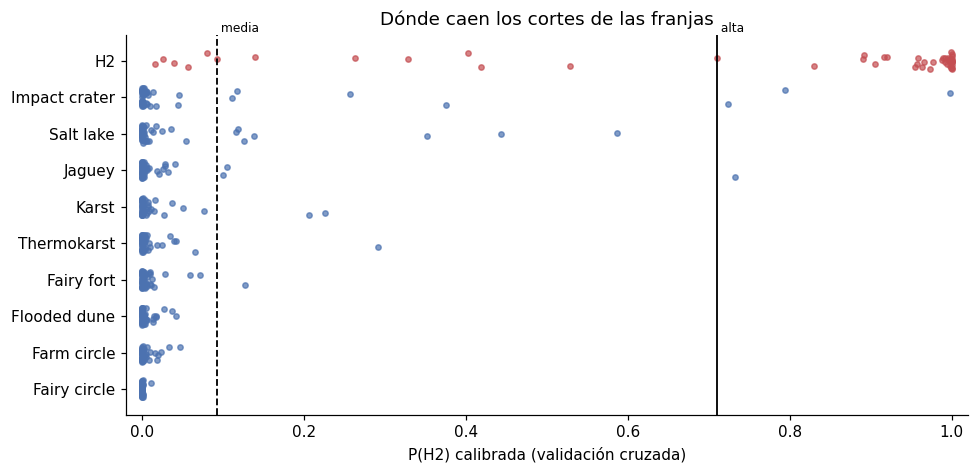

In [ ]:
p_h2, es_h2 = P_CAL[:, IDX["H2"]], y == IDX["H2"]
prec_c, rec_c, cortes = precision_recall_curve(es_h2, p_h2)
prec_c, rec_c = prec_c[:-1], rec_c[:-1]
peor_precision_desde_aqui = np.minimum.accumulate(prec_c[::-1])[::-1]
T_ALTA = float(cortes[np.argmax(peor_precision_desde_aqui >= PRECISION_ALTA)])
T_MEDIA = float(min(cortes[rec_c >= RECALL_MEDIA].max(), T_ALTA))
print(f"Franja alta: P(H2) ≥ {T_ALTA:.3f}.  Franja media: {T_MEDIA:.3f} ≤ P(H2) < {T_ALTA:.3f}.  Franja baja: P(H2) < {T_MEDIA:.3f}.")

def reparto(p, es):
    f = franja(p, T_ALTA, T_MEDIA)
    return {(f"franja {b}", q): int(((f == b) & (es if q == "H2" else ~es)).sum()) for b in ("alta", "media", "baja") for q in ("H2", "otras")}
display(pd.DataFrame({"validación cruzada": reparto(p_h2, es_h2),
                      "holdout": reparto(escalar(prob_ho, T_OPT)[:, IDX["H2"]], y_ho == IDX["H2"])}).T)

orden = pd.Series(p_h2).groupby(oof["clase"]).mean().sort_values().index
rng = np.random.default_rng(SEMILLA)
fig, ax = plt.subplots(figsize=(9, 4.4))
for fila, clase in enumerate(orden):
    v = p_h2[oof["clase"].to_numpy() == clase]
    ax.scatter(v, fila + rng.uniform(-0.25, 0.25, len(v)), s=12, alpha=0.7, color="#C44E52" if clase == "H2" else "#4C72B0")
for t, etiqueta, estilo in [(T_ALTA, "alta", "-"), (T_MEDIA, "media", "--")]:
    ax.axvline(t, color="black", lw=1.2, ls=estilo)
    ax.text(t, len(orden) - 0.3, " " + etiqueta, fontsize=8, va="bottom")
ax.set_yticks(range(len(orden)), orden); ax.set_xlim(-0.02, 1.02)
ax.set_xlabel("P(H2) calibrada (validación cruzada)"); ax.set_title("Dónde caen los cortes de las franjas")
fig.tight_layout()
plt.show()

La franja alta empieza en P(H2) = 0,710 y la media en 0,092. En validación cruzada, la franja alta reúne 38 de las 50 H2 junto con 4 imágenes de otras clases (precisión 0,90, justo el criterio); la media, 7 H2 y 17 de otras clases; y la baja deja fuera 5 H2 entre 428 imágenes de otras clases. La franja media es la zona de mezcla: allí caen las H2 con P(H2) intermedia y los cráteres, lagos salinos y Karst que más se les parecen.

En el holdout, que no intervino al fijar los cortes, el reparto es parecido: 9 de sus 10 H2 caen en la franja alta, con 2 imágenes de otras clases; la media recoge 2 imágenes de otras clases y ninguna H2; y una H2 queda en la baja. Los cortes se comportan con datos nuevos como en el desarrollo. Quedan guardados en `salidas/umbrales_prioridad.json` y no se tocan al ver las 120 estructuras.

## 4.9 H2 en una región que el modelo nunca vio

Todo lo evaluado hasta aquí, incluido el holdout, tiene un límite: las H2 de evaluación vienen de las mismas regiones del mundo que las de entrenamiento. Cuando el modelo acierta una H2 de validación ya había visto otras de su región, con su paisaje y su zoom. En La Guajira no habrá ese apoyo: no hay ninguna H2 de allí en el dataset.

Para ensayar esa situación se deja **una región fuera**. Las H2 se agrupan por región como en el notebook 3 (cadenas de saltos menores de 1.000 km). Para cada región se entrena un modelo nuevo, con el protocolo y las épocas del modelo final, usando todas las imágenes de validación cruzada menos las H2 de esa región, y luego se le muestran esas H2. El holdout no interviene.

Para las mismas imágenes se compara lo que pasaba en la validación cruzada, cuando el modelo conocía otras H2 de esa región («región conocida»), con lo que pasa ahora («región nueva»): el recall, la P(H2) mediana calibrada, la franja de la sección 4.8 en que habrían quedado y a qué clase se fueron las no reconocidas. Cada modelo tarda lo mismo que el modelo final y se guarda en `salidas/modelos/`.

In [ ]:
h2_cv = cv[cv["clase"] == "H2"].copy()
h2_cv["región"] = regiones(h2_cv["lat"], h2_cv["lon"])
oof_por_id = oof.set_index("id")
filas, destinos = [], {}
for region, sub in h2_cv.groupby("región", sort=False):
    ruta = OUT_DIR / "modelos" / ("region_fuera_" + "".join(ch if ch.isalnum() else "_" for ch in region) + ".pt")
    if ruta.exists():
        red = cargar_modelo(ruta)
    else:
        red = entrenar_con_epocas_fijas(cv[~cv["id"].isin(sub["id"])])
        guardar_modelo(red, ruta, region_fuera=region)
    ids = sub["id"].astype(int).tolist()
    prob = escalar(probabilidades(red, [CACHE[i] for i in ids]), T_OPT)
    pred = np.array([CLASES[j] for j in prob.argmax(1)])
    conocida = oof_por_id.loc[ids]
    p_conocida = escalar(conocida[[f"prob_{c}" for c in CLASES]].to_numpy(), T_OPT)[:, IDX["H2"]]
    f_nueva = franja(prob[:, IDX["H2"]], T_ALTA, T_MEDIA)
    filas.append({"región": region, "H2": len(ids), "zooms": ", ".join(map(str, sorted(sub["zoom"].unique()))),
                  "recall (conocida)": (conocida["pred"] == "H2").mean(), "recall (nueva)": (pred == "H2").mean(),
                  "P(H2) mediana (conocida)": np.median(p_conocida), "P(H2) mediana (nueva)": np.median(prob[:, IDX["H2"]]),
                  "franja alta / media / baja (nueva)": " / ".join(str(int((f_nueva == b).sum())) for b in ("alta", "media", "baja")),
                  "no reconocidas, predichas como": ", ".join(f"{c} ({n})" for c, n in pd.Series(pred[pred != "H2"]).value_counts().items()) or "—"})
    destinos[region] = pred
    del red
tabla_region = pd.DataFrame(filas).set_index("región")
display(tabla_region.round(3))
todas = np.concatenate(list(destinos.values()))
print(f"En total, {int((todas == 'H2').sum())} de {len(todas)} H2 reconocidas en una región nueva; {int((todas == 'Jaguey').sum())} predichas como Jagüey.")

,H2,zooms,recall (conocida),recall (nueva),P(H2) mediana (conocida),P(H2) mediana (nueva),franja alta / media / baja (nueva),"no reconocidas, predichas como"
región,,,,,,,,
51°N 42°E,10,"15, 16, 17, 18",0.300,0.000,0.116,0.006,0 / 1 / 9,"Karst (4), Impact crater (3), Fairy fort (2), ..."
21°S 18°E,15,"18, 19",1.000,0.533,0.992,0.813,8 / 6 / 1,"Jaguey (4), Karst (2), Impact crater (1)"
16°S 45°O,22,"17, 18",1.000,0.545,0.997,0.529,9 / 12 / 1,Impact crater (10)
34°N 79°O,3,"15, 17, 18",0.667,0.000,0.329,0.135,0 / 2 / 1,"Farm circle (1), Salt lake (1), Fairy fort (1)"


En total, 20 de 50 H2 reconocidas en una región nueva; 4 predichas como Jagüey.


Este es el resultado que más cambia la lectura del proyecto. Sacar una región del entrenamiento baja el recall de H2 de 0,84 a 0,40 en conjunto (20 de 50). Las dos regiones que el modelo reconocía perfectamente cuando las conocía (21°S 18°E y 16°S 45°O) bajan a 0,53 y 0,55, y las que ya reconocía mal (51°N 42°E y 34°N 79°O) bajan a 0. Aprender H2 en una región no basta para reconocerla en otra: una parte importante de lo que el modelo sabe de H2 es propia de cada región.

Como orden de prioridad, el resultado es mejor que como clasificación. De las 37 H2 de las dos regiones grandes, vistas como región nueva, 17 quedan en la franja alta y 18 en la media; solo 2 caen a la baja. Aunque el modelo no acierte la clase, su P(H2) sigue por encima de la de casi todas las demás clases. Las H2 de Rusia y las Carolinas, que ya se reconocían mal, quedan en la franja baja en 10 de 13 casos.

Adónde van las no reconocidas depende de la región: las de Brasil van todas a Impact crater; las de Namibia, sobre todo a Jagüey (4) y Karst; las de Rusia, a Karst, Impact crater y Fairy fort. Que parte de las H2 de Namibia, un paisaje árido con vegetación dispersa, termine como Jagüey es el mismo efecto medido en la sección 4.6.

Para La Guajira la conclusión práctica es doble. No hay que esperar que el modelo clasifique como H2 a las SCD guajiras: en una región nueva lo hizo con menos de la mitad de las H2. Y la franja media es imprescindible: en este ensayo reunió casi la mitad de las H2 de las regiones que el modelo sí aprende, así que una campaña que visitara solo la franja alta dejaría fuera muchas estructuras válidas.

## 4.10 Resultados guardados

Se guardan en `salidas/` la temperatura (`calibracion.json`), los cortes de las franjas (`umbrales_prioridad.json`) y un resumen de las cifras de este notebook (`resumen_interpretaciones.json`). El modelo final, las predicciones del holdout y los modelos de la sección 4.9 ya quedaron guardados en sus secciones.

In [ ]:
(OUT_DIR / "calibracion.json").write_text(json.dumps({"temperatura": T_OPT, "ajustada_con": "oof_predicciones.csv"}, indent=1), encoding="utf-8")
(OUT_DIR / "umbrales_prioridad.json").write_text(json.dumps({"p_h2_franja_alta_desde": T_ALTA, "p_h2_franja_media_desde": T_MEDIA, "temperatura": T_OPT}, indent=1), encoding="utf-8")
resumen = {
    "particion_hash": hash_particion(part), "variante": VARIANTE, "huella_modelo_final": HUELLA_MODELO, "epocas_modelo_final": EPOCAS_FINALES,
    "temperatura": T_OPT, "ece_validacion_cruzada": {"sin_calibrar": ece_antes, "calibrado": ece_despues},
    "holdout": {m: {"valor": float(v), "ic95": [float(remuestreos[m].quantile(0.025)), float(remuestreos[m].quantile(0.975))]}
                for m, v in metricas_holdout(y_ho, p_ho, prob_ho[:, i_h2]).items()},
    "holdout_f1_macro_9_clases": float(f1_ho_9),
    "contexto_f1_macro": tabla_ctx["F1-macro"].round(4).to_dict(),
    "montajes": tabla_m.round(4).to_dict(orient="index"),
    "franjas": {"alta_desde": T_ALTA, "media_desde": T_MEDIA},
    "region_nueva": {r: {"recall_conocida": float(f["recall (conocida)"]), "recall_nueva": float(f["recall (nueva)"])} for r, f in tabla_region.iterrows()},
}
(OUT_DIR / "resumen_interpretaciones.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print("Guardado en", OUT_DIR)

Guardado en salidas


## Resumen

- **Modelo final:** YOLOv8n entrenado con las 499 imágenes de validación cruzada (16 épocas en la etapa 1 y 7 en la etapa 2) y congelado.
- **Holdout:** F1-macro de 0,919 (IC 95 %: 0,866 a 0,966, sorteando sitios), dentro del rango de la validación cruzada pero en su parte baja. Para H2, F1 de 0,857 y PR-AUC de 0,949, con intervalos anchos (10 imágenes de 8 sitios).
- **Calibración:** T = 1,03; el modelo ya estaba razonablemente calibrado. P(H2) es fiable cerca de 0 y de 1, donde está el 94 % de las imágenes; los valores intermedios son zona de duda.
- **Contexto:** F1-macro de 0,936 con la imagen original, 0,767 sin color, 0,717 con solo el centro y 0,826 con solo el entorno, confirmados por los controles con desenfoque. Perder el entorno cuesta más (0,23) que perder la estructura (0,10). H2 conserva su recall pero su precisión cae hasta 0,63: sin paisaje se vuelve una clase refugio.
- **Estructura y paisaje en conflicto:** una H2 sobre paisaje guajiro se reconoce solo en el 33 % de los montajes (84 % en el control) y en la mitad pasa a Jagüey.
- **Mapas de calor:** en H2 la atención media cae sobre todo fuera de la depresión; en las demás clases, sobre la estructura o su borde.
- **Franjas de prioridad,** fijadas antes de ver las 120: alta si P(H2) ≥ 0,710 y media si P(H2) ≥ 0,092. En el holdout, 9 de las 10 H2 caen en la franja alta.
- **Región nueva:** sin su región en el entrenamiento, el recall de H2 baja de 0,84 a 0,40, pero 35 de las 37 H2 de las regiones que el modelo sí aprende quedan en franja alta o media.

**Qué se puede afirmar.** El modelo distingue bien las diez clases dentro de las regiones que conoce. Lo que no está demostrado es que reconozca una SCD de una región nueva por su forma: depende en buena parte del paisaje, y el de La Guajira lo empuja hacia Jagüey. Sobre las 120 estructuras sirve como orden de prioridad (las franjas alta y media juntas recuperan casi todas las H2 de una región nueva que el modelo aprende), no como clasificador: que una estructura guajira salga como Jagüey no la descarta.